# Script

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import numpy as np
import torch
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from matplotlib import pyplot as plt

from imlff.analysis.plotting_ws import plot_cost_delta
from imlff.data.info import molecule_to_dataset
from imlff.common.util import proj_path
from imlff.data.info import molecule_to_atomic_numbers, Z_to_symbol, molecule_to_n_atoms
from imlff.analysis.warmstart_summarize import populate_dic_arrays, prepare_explicit_cohort, load_or_build_df_explicit, get_loosest_tols_with_tolerable_fmae, plot_scatter_tols_for_tolerable_fmae, gather_vals, add_threshold_borders_scatter, arch2marker
from imlff.analysis.warmstart_summarize import (
    WarmstartLoadConfig, load_best_runs, select_cohort, load_or_build_df_deq,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
## Config ##

cfg = WarmstartLoadConfig(
    runs_file_tag='2026-06-25_ALL_128/runs_best_per_group_test',

    which_tag='best_manual',  # see next cell for alternative tag options

    # cohort filters: list of query strings, joined with ' and '.
    # Comment lines out to disable, uncomment to include.
    selected_query=[
        '(("deq" == type) or ("deq-merged" == type)) == (jac_reg_strength == 0.32)',
        'n_z == 128',
    ],
    not_run_ids=(),

    # warmstart sweep (cold variant commented below)
    warmstart_configs=[
        # dict(z=0, g_bar=0),
        # dict(z=1, g_bar=0),
        dict(z=1, g_bar=1),
    ],
    default_forw_tol=0.01,
    default_back_tol=0.01,
    back_iter_on_g_bar=True,
    saving_postfix='',


    should_collect_extra_data=False,
    only_mean=True,
    overweigh_back=1.,
)

In [ ]:
## COLD - Config ##

cfg = WarmstartLoadConfig(
    runs_file_tag='2026-06-25_ALL_128/runs_best_per_group_test',

    which_tag='best_manual',  # see next cell for alternative tag options

    selected_query=[
        'n_z == 128',
        'type == "deq"',
        'jac_reg_strength == 0.32',
        'molecule == "double-walled_nanotube"', # ... get last datapoint
    ],
    not_run_ids=(),

    # cold-start variant:
    warmstart_configs=[dict()],
    default_forw_tol=0.,
    default_back_tol=0.,
    saving_postfix='_cold',

    should_collect_extra_data=False,
    only_mean=True,
    overweigh_back=1.,
)

In [10]:
best_runs_per_group = load_best_runs(cfg)
selected = select_cohort(best_runs_per_group, cfg)
print('#best_runs:', len(best_runs_per_group), cfg.runs_file_tag)
print('#selected:', len(selected),
      '#deq:', (selected.type == 'deq').sum(),
      '#deq merged:', (selected.type == 'deq-merged').sum(),
      )


#best_runs: 535 2026-06-25_ALL_128/runs_best_per_group_test
#selected: 484 #deq: 53 #deq merged: 0


In [ ]:
## DEQ load ##
reload = False
# save = False; save = 'force'; save = True
save = 'force'

if 'dic_arrays' in locals():
    print('dic arrays present. entries:', len(dic_arrays))
else:
    print('dic_arrays not present')
    dic_arrays = {}

df_deq, dic_arrays = load_or_build_df_deq(
    selected, cfg, dic_arrays, reload=reload, save=save,
)
df_deq['Dataset'] = df_deq.molecule_name.apply(molecule_to_dataset)

## Scatter plot

In [18]:
df_deq_selected = df_deq.query('type=="deq"').copy()
len(df_deq_selected)

53759

In [ ]:
selected_query = 'type=="deq"'
selected_query = f'({selected_query}) and Rep=="PaiNN"'
selected_query = f'({selected_query}) and molecule_name in ["uracil", "toluene", "malonaldehyde", "double-walled_nanotube"]'
# selected_query = f'({selected_query}) and molecule_name in ["double-walled_nanotube"]'

df_deq_selected = df_deq.query(selected_query).copy()
# df_deq_selected = df_deq.query(' (molecule_name == "aspirin")')

len(df_deq_selected)

5542

In [42]:
df_loosest_tolerable = get_loosest_tols_with_tolerable_fmae(df_deq_selected)

3 1 8 ['Molecule', 'Malonaldehyde  (5.0)', 'Uracil  (6.7)', 'Toluene  (7.4)', 'iter_mean', '5.0008', '6.670925', '7.41345']
{'Malonaldehyde  (5.0)': 'MD17', 'Toluene  (7.4)': 'MD17', 'Uracil  (6.7)': 'MD17'}


<Axes: xlabel='Backward tolerance', ylabel='Forward tolerance'>

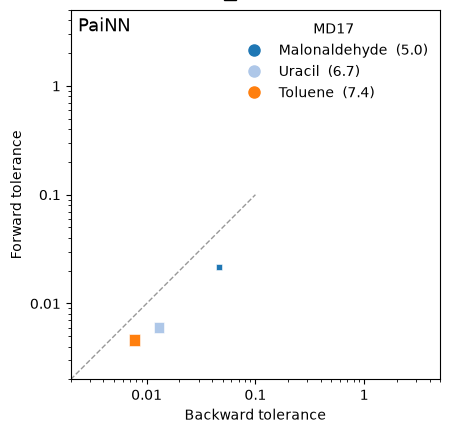

In [ ]:
plot_scatter_tols_for_tolerable_fmae(
    df_loosest_tolerable, back_iter_on_g_bar=cfg.back_iter_on_g_bar,
    group_by='Architecture', marker_size="iter_mean", save=False, show=False, marker_size_legend=False)

plt.gcf().savefig()

1 3 8 ['iter_mean', '3.908175', '6.142', '7.380575', 'Architecture', 'PaiNN (6.1)', 'SO3net (7.4)', 'SchNet (3.9)']


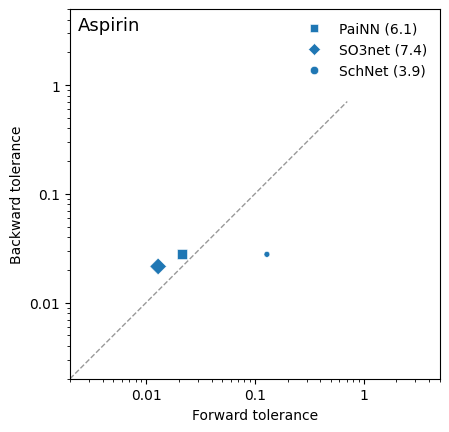

In [ ]:
plot_scatter_tols_for_tolerable_fmae(df_loosest_tolerable, back_iter_on_g_bar=cfg.back_iter_on_g_bar, group_by='Molecule', save=0, marker_size_legend=False)

## FMAE crossing as a function of Ftol, Btol

In [ ]:
df_deq_selected = df_deq.query('molecule_name == "aspirin"')

In [28]:
ftols = np.sort(df_deq_selected.forw_tol.unique())
btols = np.sort(df_deq_selected.back_tol.unique())

tols = np.sort(np.unique(np.concatenate([
    df_deq_selected.forw_tol.values,
    df_deq_selected.back_tol.values
])))

ftols = tols
btols = tols


dic_vals_Fmae      = gather_vals(df_deq_selected, ftols, btols, value_key="F_mae_mean")    
dic_vals_forw_iter = gather_vals(df_deq_selected, ftols, btols, value_key="forw_iter_mean")    
dic_vals_back_iter = gather_vals(df_deq_selected, ftols, btols, value_key="back_iter_mean")    

for k in dic_vals_Fmae:
    print(k)

100%|██████| 3/3 [00:01<00:00,  2.45it/s]

('aspirin', 'PaiNN', -1, -1)
('aspirin', 'SO3net', -1, -1)
('aspirin', 'SchNet', -1, -1)


### Warm back_on_g_bar

In [39]:
molecules = 'aspirin',

0
7
0
14
0
15
1 3 8 ['iter_mean', '3.908175', '6.142', '7.380575', 'Architecture', 'PaiNN (6.1)', 'SO3net (7.4)', 'SchNet (3.9)']


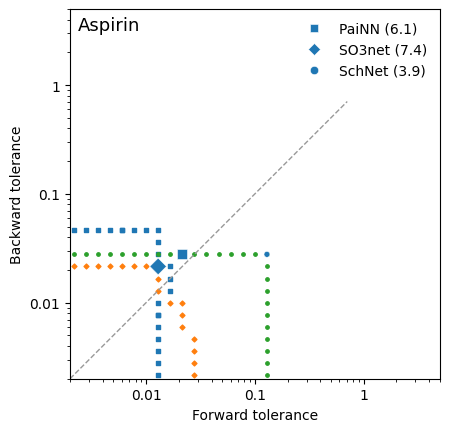

~/imlff/../imlff-paper/figures/scatter__ftol_btol_for_tolerable_Fmae__aspirin__with_border.pdf


<Figure size 640x480 with 0 Axes>

In [ ]:
fig, ax = plt.subplots()

vmin_mapp = selected.query('type=="deq"')[['AtomisticRepresentationClass', 'molecule', 'best_manual__test_mi10_forces_MAE']].set_index(['AtomisticRepresentationClass', 'molecule'])

for k in [
    ('aspirin', 'PaiNN', -1, -1),  
    ('aspirin', 'SO3net', -1, -1),  
    ('aspirin', 'SchNet', -1, -1),  
]:
    Z = dic_vals_Fmae[k].T
    thr=vmin_mapp.loc[(k[1], k[0])].item() * 1.02
    marker = arch2marker[k[1]]
    add_threshold_borders_scatter(Z, ftols, btols, thr=thr, ax=ax, s=6, marker=marker)

plot_scatter_tols_for_tolerable_fmae(
    df_loosest_tolerable.query('molecule_name=="aspirin"'),
    group_by='Molecule', marker_size="iter_mean", save=False,
    put_on_ax=ax
    )

pat = proj_path('../imlff-paper/figures/scatter__ftol_btol_for_tolerable_Fmae__aspirin__with_border.pdf')
plt.savefig(pat, bbox_inches='tight')
print(pat)

# Analysis

### Pick pareto front

In [94]:

only_symmetric_tol = False
only_symmetric_tol = True



### DEQ (max tol) -- filter
# To df, filter for the ones on pareto front
df_means_list = []
# for model_tag, z, g_bar in df_deq[['model_tag', 'z', 'g_bar']].drop_duplicates().itertuples(index=False):
#     df_means = df_deq.query(f'model_tag==@model_tag and z==@z and g_bar==@g_bar').copy()

df_deq_filtered = df_deq
if only_symmetric_tol:
    df_deq_filtered = df_deq[df_deq.forw_tol == df_deq.back_tol]

for (model_tag, z, g_bar), df_means in df_deq_filtered.groupby(['model_tag', 'z', 'g_bar']):
    if len(df_means):
        df_means = df_means.sort_values(by=['cost_mean', 'F_mae_mean'])
        is_improving = (df_means['F_mae_mean'] < df_means['F_mae_mean'].expanding().min().shift(1)) & (df_means['cost_mean'].diff() > 0)
        is_improving.iloc[0] = True
        df_means = df_means[is_improving]
        df_means_list.append(df_means)
    
df_means = pd.concat(df_means_list)

In [95]:

for (model_tag, z, g_bar), df_means_debug in df_deq.groupby(['model_tag', 'z', 'g_bar']):
    # print((model_tag, z, g_bar))
    df_means_debug = df_means_debug.sort_values(by=['cost_mean', 'F_mae_mean']).copy()
    is_improving = (df_means_debug['F_mae_mean'] < df_means_debug['F_mae_mean'].expanding().min().shift(1)) & (df_means_debug['cost_mean'].diff() > 0)
    is_improving.iloc[0] = True
    df_means_debug['imp'] = is_improving
    # break

### Parse Explicit models

In [96]:
## Explicit cohort prep ##
selected_take_tt = prepare_explicit_cohort(selected)

In [ ]:
## Explicit load ##
reload = False
# save = True; save = 'force'
save = 'force'

df_explicit = load_or_build_df_explicit(
    selected_take_tt, cfg, reload=reload, save=save,
)
print('df_explicit:', len(df_explicit), cfg.df_explicit_path)

### Unite DFs

In [ ]:
### Unite DFs

DEQ_CHOICE = 'deq-merged'

df_all = df_means.query('type==@DEQ_CHOICE').explode(['forw_iter', 'back_iter', 'F_mae'])
df_all['sample'] = df_all.groupby(level=0).cumcount()
df_all['tol_strategy'] = df_all.index
df_all['type'] = 'deq_tol'
df_all = df_all.reset_index(drop=True)

df_all = pd.concat([df_all, df_explicit], ignore_index=True)

df_all.Rep.fillna('uncategorized', inplace=True)
df_all.molecule_name.fillna('uncategorized', inplace=True)
df_all['F_mae'] = df_all['F_mae'].astype(float)

df_all.forw_tol = df_all.forw_tol.fillna(-1)
df_all.back_tol = df_all.back_tol.fillna(-1)

pat = cfg.df_all_path
df_all.to_csv(pat)

## Number Crunching

In [ ]:
## For paper ##

gcols = ['z', 'g', 'g_bar', 'Rep', 'Dataset', 'molecule_name', 'model_tag']
gcols = [c for c in gcols if c in df_deq.columns]

best_per_molecule = (
    pd.concat(
        [df_deq[df_deq['cost_mean'] <= c].assign(cost_budget=c) for c in [1, 2, 3, 4, 5, 6, 7, 8]],
        ignore_index=True
    )
    .sort_values('F_mae_mean')
    .groupby(gcols + ['cost_budget'])
    .first()
)
best_per_dataset = (
    best_per_molecule.reset_index()
    .groupby(gcols[:-2] + ['cost_budget'], as_index=True)\
    ['F_mae_mean'].agg(['mean']).round(2).T
)
best_per_dataset

z               1                                                              \
g              -1                                                               
g_bar           1                                                               
Rep         PaiNN                                                               
Dataset      MD17                                            MD22               
cost_budget     1     2     3     4     5     6     7     8     1     2     3   
mean         0.37  0.33  0.33  0.33  0.33  0.33  0.33  0.33  0.39  0.26  0.24   

z                                                                              \
g                                                                               
g_bar                                                                           
Rep                                       SO3net                                
Dataset                                     MD17                                
cost_budget     4     5     6     7     8      1    2     3     4     5     6   
mean         0.24  0.24  0.24  0.24  0.24   0.25  0.2  0.19  0.19  0.19  0.19   

z                                                                              \
g                                                                               
g_bar                                                                           
Rep                                                                    SchNet   
Dataset                 MD22                                             MD17   
cost_budget     7     8    1     2     3     4     5     6     7     8      1   
mean         0.19  0.19  0.6  0.37  0.32  0.32  0.32  0.32  0.32  0.32    0.8   

z                                                                              \
g                                                                               
g_bar                                                                           
Rep                                                                             
Dataset                                                MD22                     
cost_budget     2     3     4     5     6     7     8     1     2     3     4   
mean         0.76  0.75  0.75  0.75  0.75  0.75  0.75  1.38  1.27  1.25  1.25   

z                                    
g                                    
g_bar                                
Rep                                  
Dataset                              
cost_budget     5     6     7     8  
mean         1.25  1.25  1.25  1.25

## Plotting

1 3


~/imlff/src/imlff/analysis/plotting_ws.py:884: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/tmp/ipykernel_3157636/3481004108.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


~/imlff/../imlff-paper/figures/warmstart_accuracy/warmstart_accuracy_dataset_median_q25_q75_relative_datasets_aggregated_agg_first_symmetric_tol.pdf


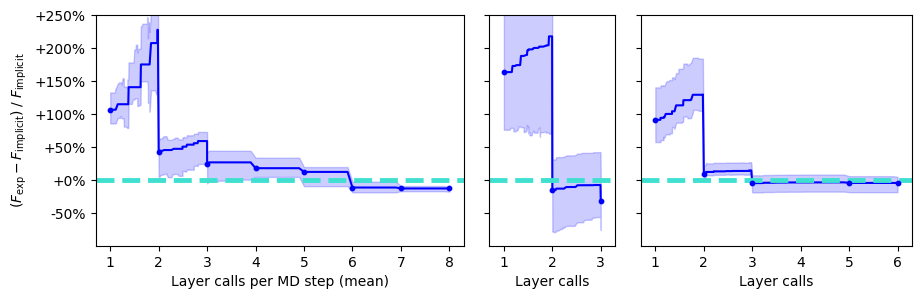

1 3


~/imlff/src/imlff/analysis/plotting_ws.py:884: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/tmp/ipykernel_3157636/3481004108.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


~/imlff/../imlff-paper/figures/warmstart_accuracy/warmstart_accuracy_dataset_median_q25_q75_relative_datasets_as_lines_agg_first_symmetric_tol.pdf


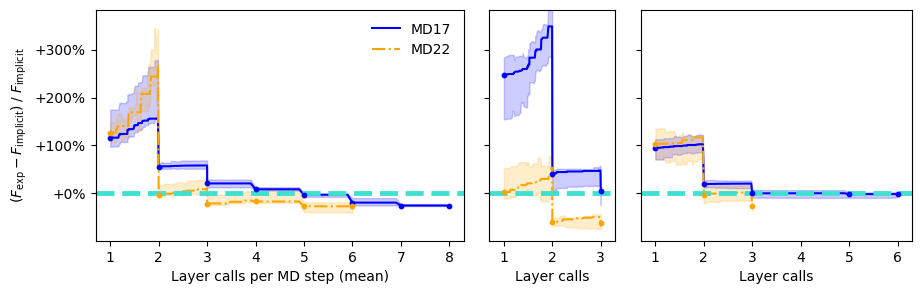

1 3


~/imlff/src/imlff/analysis/plotting_ws.py:884: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/tmp/ipykernel_3157636/3481004108.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


~/imlff/../imlff-paper/figures/warmstart_accuracy/warmstart_accuracy_dataset_median_q25_q75_relative_datasets_aggregated_symmetric_tol.pdf


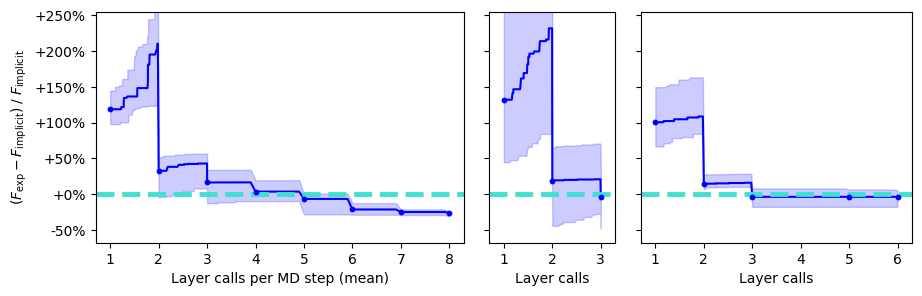

1 3


~/imlff/src/imlff/analysis/plotting_ws.py:884: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/tmp/ipykernel_3157636/3481004108.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


~/imlff/../imlff-paper/figures/warmstart_accuracy/warmstart_accuracy_dataset_median_q25_q75_relative_datasets_as_lines_symmetric_tol.pdf


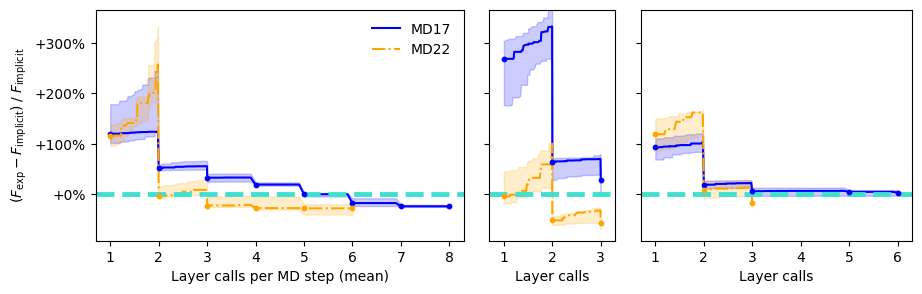

In [128]:
# --- Aggregated, n_z as rows ---


for show_median in [
    True,
    # False
]:
    for aggregate_then_delta in [
        True,
        False
    ]:
        for aggregate_over_datasets in [
            True,
            False,
        ]:
            
            for normalize in [
                'relative', 
                # 'delta', 
                # 'relative_symmetric'
                ]:
                
                stats_str = 'median_q25_q75' if show_median else 'mean_conf_intervall'
                
                if not aggregate_over_datasets:
                    postfix = '_datasets_as_lines'
                    aggregate_over='dataset', 'n_z'
                    series_styles = [
                        dict(type="explicit", Dataset="MD17", linestyle="-",  label="MD17", color='blue'),
                        dict(type="explicit", Dataset="MD22", linestyle="-.", label="MD22", color='orange'),
                    ]
                    ylim = (-1,5) if show_median else (-1.5,4)
                    
                else:
                    postfix = '_datasets_aggregated'
                    aggregate_over='all'
                    series_styles = [
                        dict(type="explicit", linestyle="-",  color='blue'),
                    ]
                    ylim = (-1,5) if show_median else (-1.5,4)
                    
                if aggregate_then_delta:
                    postfix += '_agg_first'
                if only_symmetric_tol:
                    postfix += '_symmetric_tol'
                    
                xlabel_desc=['Layer count (mean)', 'Layer count', 'Layer count']
                xlabel_desc=[
                    'Costs per MD step (in layer calls, mean)',
                    'Costs',
                    'Costs'
                ]
                xlabel_desc=[
                    'Layer calls per MD step (mean)',
                    'Layer calls',
                    'Layer calls'
                ]

                
                fig, axs = plot_cost_delta(
                    df_all,#[(df.type!='explicit-tied') & (df.Rep=='PaiNN') & (df.Dataset=='MD17')],
                    col="Rep",
                    band=(25, 75),
                    ylim='lines',
                    normalize=normalize,
                    include_dominated=True,
                    verbose=False,
                    legend=(0,0),
                    xlabel_desc=xlabel_desc,
                    
                    xpad = .3,
                    
                    aggregate_over=aggregate_over,
                    series_styles=series_styles,
                    
                    title_pos=(.05, .05),
                    show_median=show_median,
                    
                    bins_per_unit=10,
                    aggregate_then_delta=aggregate_then_delta,
                )
                
                for ax in axs.flatten():
                    a,b = ax.get_ylim()
                    a = max(a, ylim[0])
                    b = min(b, ylim[1])
                    ax.set_ylim((a,b))
                
                plt.tight_layout()
                plot_path = '../imlff-paper/figures/warmstart_accuracy'
                pat = proj_path(f'{plot_path}/warmstart_accuracy_dataset_{stats_str}_{normalize}{postfix}.pdf')
                print(pat)
                fig.savefig(pat, bbox_inches="tight")
                plt.show()

1 3


~/imlff/src/imlff/analysis/plotting_ws.py:884: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


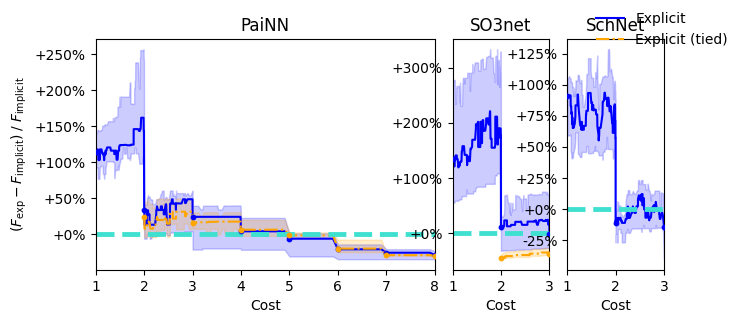

In [144]:

fig, axs = plot_cost_delta(
    df_all,
    xlabel_desc='Cost',
    aggregate_over='dataset',
    sharey=False,
    normalize='relative'
)
